## Preprocessing

tujuan: skrining dysglycemia (PGclass3: 0 = NGR, 1 = prediabetes, 2 = DM) tanpa tes gula darah.

semua fungsi preprocessing ada di `preprocessing.py`. notebook ini hanya memanggil, memeriksa, dan menyimpan hasilnya.

dua tahap:
1. `prepare()`: aturan tetap, tidak memakai statistik data, aman dijalankan sebelum split.
2. `stats_cleaner`: langkah yang butuh statistik (kolom kosong, biner jarang, korelasi, skewness, imputasi). **tidak dijalankan untuk menyimpan data**, karena harus di-fit di data latih saja. di `02-modeling.ipynb` ia jadi langkah pertama pipeline dan di-fit ulang di tiap fold. di sini hanya didemokan di bagian latih.

yang disimpan ke `data/processed/`: hasil `prepare()` + kolom `split` (test dikunci) + target, feature set, dan laporan.

### Import

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from preprocessing import (
    buat_split, config, feature_sets, load_raw, metrik_tiga_kelas, prepare, stats_cleaner, terapkan_lipatan,
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 90)

SKEMA_TEST = "temporal"     # test dikunci: 30% terakhir menurut urutan ID (lihat Skema Pembagian Data)
FOLDER_OUT = Path("data/processed")
FOLDER_OUT.mkdir(parents=True, exist_ok=True)
NAMA_KELAS = {0: "NGR", 1: "Prediabetes", 2: "DM"}

### Load Data

In [2]:
raw = load_raw("data/Dataset for diabetes research.csv")
print("data mentah:", raw.shape)

data mentah: (5922, 190)


### Aturan Tetap: prepare()

populasi: yang sudah tahu DM (DMhis = 1) dikeluarkan, karena tujuannya mencari yang belum tahu.

In [3]:
x, y, meta, laporan = prepare(raw)
print("fitur setelah prepare():", x.shape)
print("target:", y.map(NAMA_KELAS).value_counts().to_dict())
print()
for baris in laporan.attrs["catatan"]:
    print("-", baris)

fitur setelah prepare(): (5873, 93)
target: {'NGR': 4444, 'Prediabetes': 1121, 'DM': 308}

- populasi skrining: 5922 -> 5873 orang (DMhis == 1 dikeluarkan)
- riwayat_tidak_diisi: 689 orang menjawab 9 di semua 15 pertanyaan
- riwayat semua kosong (bukan 9): 242 orang, tidak ditandai (lihat sel Verifikasi Asumsi)
- HypertenHis: 5681 kosong diisi 0 (asumsi: kosong = tidak)
- DyslipideHis: 5833 kosong diisi 0 (asumsi: kosong = tidak)
- DMhighrisk: 1805 kosong diisi 0 (asumsi: kosong = tidak)
- ThalussemiaHPLC: 5728 kosong diisi 0 (asumsi: kosong = tidak)
- SmokingRange: 2856 kosong struktural (Smoking == 1) diisi 0
- DrinkYears: 2494 kosong struktural (Drinking == 1) diisi 0
- Drink50g: 2530 kosong struktural (Drinking == 1) diisi 0
- tidak wajar: kreatinin < 35 (SCRE, GFR ikut): 327 baris jadi NaN
- tidak wajar: eGFR > 200 (GFR): 374 baris jadi NaN
- tidak wajar: tinggi < 120 (Height, BMI): 2 baris jadi NaN
- tidak wajar: tensi atas <= bawah: 2 baris jadi NaN
- tidak wajar: LDL > kolester

yang dikerjakan `prepare()`:
- `Gender` (kamus 0/1, data 1/2) diganti `male` (1 = laki-laki).
- 689 orang menjawab 9 di semua 15 pertanyaan riwayat penyakit. dibuat satu penanda `riwayat_tidak_diisi`, lalu kode 9 jadi NaN. kode 9 di `WeightLoss` dan `Cancer` juga jadi NaN.
- kolom bendera (`HypertenHis`, `DyslipideHis`, dst.) hanya berisi 1 atau kosong. kosong diasumsikan 0 (tidak).
- `SmokingRange`, `DrinkYears`, `Drink50g` kosong karena tidak ditanya ke yang tidak merokok / minum, diisi 0.
- nilai tidak wajar jadi NaN: kreatinin < 35 (eGFR ikut, karena dihitung dari kreatinin), eGFR > 200, tinggi < 120, tensi atas <= bawah, LDL > kolesterol total.
- 242 orang lain mengosongkan seluruh 15 pertanyaan riwayat (bukan menjawab 9). mereka **tidak** ditandai `riwayat_tidak_diisi`, hanya tampak sebagai NaN.

#### Kolom yang dibuang dan alasannya

In [4]:
ringkas = laporan["alasan"].str.replace(r"\(.*\)", "", regex=True).str.strip().value_counts()
ringkas.to_frame("jumlah kolom")

,jumlah kolom
alasan,
turunan kategori dari versi numerik,37
bocor: gula darah atau dihitung dari gula darah,12
"kuesioner kesadaran diabetes, mayoritas tidak tahu",7
"kosong struktural, informasi ada di kolom penyaring",7
komplikasi diabetes,5
tes gula darah lain,4
label atau turunan label,4
"jawaban mentah per kerabat, diringkas oleh DMfamilyHistory",4
id / tanggal / target,3


In [5]:
for alasan, grup in laporan.groupby("alasan"):
    print(f"[{len(grup)}] {alasan}")
    print("    ", ", ".join(grup["kolom"]))

[1] bocor: bernilai 1 bila MCV < 80 DAN glukosa abnormal (kelas >= 1); 99,7% cocok
     ThalussemiaAND
[1] bocor: bernilai 9 hanya bila FPG >= 6,1 (69% dari FPG >= 6,1; tidak pernah pada FPG < 6,1)
     VAR00001
[12] bocor: gula darah atau dihitung dari gula darah
     FPG, PG2h, GLU, HomaIR, Homaβ, ISIGutt, INS2h, CP2h, FINS, FCP, FPGover7, P2PGover11
[1] diganti kolom male (1 = laki-laki)
     Gender
[1] ditahan: bendera 1/kosong, hampir semua kosong; manfaat belum jelas
     ThalussemiaHPLC
[1] ditahan: komposit risiko, definisi tidak ada di kamus
     DMhighrisk
[1] ditahan: turunan hitung darah (MCV < 80), redundan dengan MCV/MCH
     ThalussemiaOR
[1] duplikat: akar kuadrat dari ALT
     ALT.1
[3] id / tanggal / target (disimpan terpisah)
     NO, Data, PGclass3
[4] jawaban mentah per kerabat, diringkas oleh DMfamilyHistory
     FatherDM, MotherDM, BSDM, ChildDM
[2] kolom teks
     EscDrinkD, EyeDia
[5] komplikasi diabetes (setelah diagnosis)
     DF, MADPN, TFDPN, DR, DRyd
[1] k

### Verifikasi Asumsi

asumsi "kosong karena tidak ditanya" perlu dicek: apakah kosongnya benar hanya pada yang tidak merokok / minum?

In [6]:
df = raw[raw["DMhis"] == 0]
for kolom, penyaring in [("SmokingRange", "Smoking"), ("DrinkYears", "Drinking"), ("Drink50g", "Drinking")]:
    print(kolom, "kosong menurut", penyaring, "(1 = tidak, 2 = kadang, 3 = rutin):")
    print(pd.crosstab(df[penyaring], df[kolom].isna().rename("kosong")).to_string())
    print()

SmokingRange kosong menurut Smoking (1 = tidak, 2 = kadang, 3 = rutin):
kosong   False  True 
Smoking              
1.0          6   2856
2.0        276     68
3.0       1701    569

DrinkYears kosong menurut Drinking (1 = tidak, 2 = kadang, 3 = rutin):
kosong    False  True 
Drinking              
1.0          44   2494
2.0        1079    603
3.0         847    329

Drink50g kosong menurut Drinking (1 = tidak, 2 = kadang, 3 = rutin):
kosong    False  True 
Drinking              
1.0           8   2530
2.0          95   1587
3.0         288    888



- `SmokingRange` dan `DrinkYears`: hampir semua yang menjawab "tidak" kosong (2.856 dari 2.862 bukan perokok; 2.494 dari 2.538 bukan peminum), jadi diisi 0. kosong pada perokok dan peminum (24% dan 32%) dibiarkan NaN karena itu memang tidak diketahui.
- `Drink50g` (jumlah minum per kali): tetap kosong pada sebagian besar yang minum, jadi isinya tidak lengkap. biasanya terbuang oleh `stats_cleaner` karena kosong > 50%.

### Skema Pembagian Data

tiga skema tersedia di `buat_split`. urutan ID hampir sama dengan urutan tanggal survei (korelasi spearman 0,9995; hanya 2 pasangan berurutan yang mundur, paling jauh 2 hari), jadi `temporal` bisa dibuat dari ID.

**test set dikunci = skema temporal**: 70% awal (urut ID) untuk latih, 30% akhir untuk uji. alasannya, ini satu-satunya skema yang menguji model pada data yang datang sesudah data latih, jadi lebih jujur daripada split acak. bagian uji tidak dipakai sama sekali sampai model final dipilih. semua eksperimen (ablasi di bawah, CV di `02-modeling.ipynb`) hanya memakai bagian latih.

In [7]:
for skema in ["acak", "tanggal", "temporal"]:
    lipatan = buat_split(y, meta, skema)
    info = [(len(tr), len(te), int((y.iloc[te] == 2).sum())) for tr, te in lipatan]
    print(f"{skema:9s} {len(lipatan)} lipatan | (latih, uji, DM di uji): {info}")
urut = meta.sort_values("NO")
selisih_hari = urut["Data"].diff().dt.days
print()
print("spearman urutan ID vs tanggal:", round(meta["NO"].rank().corr(meta["Data"].rank()), 4))
print("pasangan ID berurutan yang tanggalnya mundur:", int((selisih_hari < 0).sum()), "| paling jauh", int(-selisih_hari.min()), "hari")

acak      5 lipatan | (latih, uji, DM di uji): [(4698, 1175, 62), (4698, 1175, 62), (4698, 1175, 62), (4699, 1174, 61), (4699, 1174, 61)]
tanggal   5 lipatan | (latih, uji, DM di uji): [(4711, 1162, 54), (4692, 1181, 49), (4687, 1186, 61), (4693, 1180, 56), (4709, 1164, 88)]
temporal  1 lipatan | (latih, uji, DM di uji): [(4111, 1762, 69)]

spearman urutan ID vs tanggal: 0.9995
pasangan ID berurutan yang tanggalnya mundur: 2 | paling jauh 2 hari


In [8]:
idx_latih, idx_uji = buat_split(y, meta, SKEMA_TEST)[0]
split = pd.Series("train", index=y.index)
split.iloc[idx_uji] = "test"

print("periode latih:", meta["Data"].iloc[idx_latih].min().date(), "s/d", meta["Data"].iloc[idx_latih].max().date())
print("periode uji  :", meta["Data"].iloc[idx_uji].min().date(), "s/d", meta["Data"].iloc[idx_uji].max().date())
tabel = pd.crosstab(y.map(NAMA_KELAS), split, margins=True).loc[["NGR", "Prediabetes", "DM", "All"]]
tabel.join((pd.crosstab(y.map(NAMA_KELAS), split, normalize="columns") * 100).round(1).add_suffix(" %"))

periode latih: 2012-02-10 s/d 2012-03-12
periode uji  : 2012-03-12 s/d 2012-04-07


col_0,test,train,All,test %,train %
PGclass3,,,,,
NGR,1424,3020,4444,80.8,73.5
Prediabetes,269,852,1121,15.3,20.7
DM,69,239,308,3.9,5.8
All,1762,4111,5873,NaN,NaN


In [9]:
# bagian latih saja, index direset supaya buat_split / terapkan_lipatan bisa dipakai langsung
x_tr = x.iloc[idx_latih].reset_index(drop=True)
y_tr = y.iloc[idx_latih].reset_index(drop=True)
meta_tr = meta.iloc[idx_latih].reset_index(drop=True)
print("bagian latih:", x_tr.shape)

bagian latih: (4111, 93)


### Tahap Statistik: stats_cleaner

didemokan dengan fit di seluruh bagian latih, hanya untuk melihat apa yg dilakukannya. di modeling, ia di-fit ulang di tiap fold sehingga kolom yg dibuang bisa sedikit berbeda antar fold.

In [10]:
hasil = {}
for imputasi in ["none", "median"]:
    c = stats_cleaner(imputasi=imputasi).fit(x_tr)
    hasil[imputasi] = (c, c.transform(x_tr))
    print(f"imputasi = {imputasi:6s} -> {hasil[imputasi][1].shape} | NaN: {int(hasil[imputasi][1].isna().sum().sum())}")

c, x_bersih = hasil["none"]
print()
print("kolom dibuang di tahap statistik:", len(c.dibuang_))
pd.Series(c.dibuang_, name="alasan").to_frame()

imputasi = none   -> (4111, 80) | NaN: 19867


imputasi = median -> (4111, 80) | NaN: 0

kolom dibuang di tahap statistik: 13


,alasan
PLCR,kosong 78% (> 50%)
Drink50g,kosong 52% (> 50%)
Cancer,kosong 100% (> 50%)
HCVAb,biner terlalu jarang (minoritas = 6)
PAD,biner terlalu jarang (minoritas = 7)
CerebralHe,biner terlalu jarang (minoritas = 4)
TIA,biner terlalu jarang (minoritas = 6)
MI,biner terlalu jarang (minoritas = 2)
HF,biner terlalu jarang (minoritas = 5)
CAP,biner terlalu jarang (minoritas = 3)


In [11]:
print("fitur akhir:", len(c.kolom_))
print("kolom di-log1p (skewness > 2):", c.kolom_log_)
sisa = x_bersih.isna().mean().mul(100)
print(f"kolom yang masih punya NaN: {int((sisa > 0).sum())} dari {len(sisa)}; kosong maksimum {sisa.max():.1f}%")

fitur akhir: 80
kolom di-log1p (skewness > 2): ['ALT', 'AST', 'ASTALT', 'GGT', 'ALP', 'TBIL', 'DBIL', 'TG', 'BUN', 'SCRE', 'UmALB', 'UMAUCR', 'LCcount', 'ALY', 'ALYcount', 'RDWCV', 'BASO', 'BASOcount', 'EOcount', 'PLT', 'FIB4']
kolom yang masih punya NaN: 74 dari 80; kosong maksimum 27.5%


#### Sebelum dan sesudah: skewness

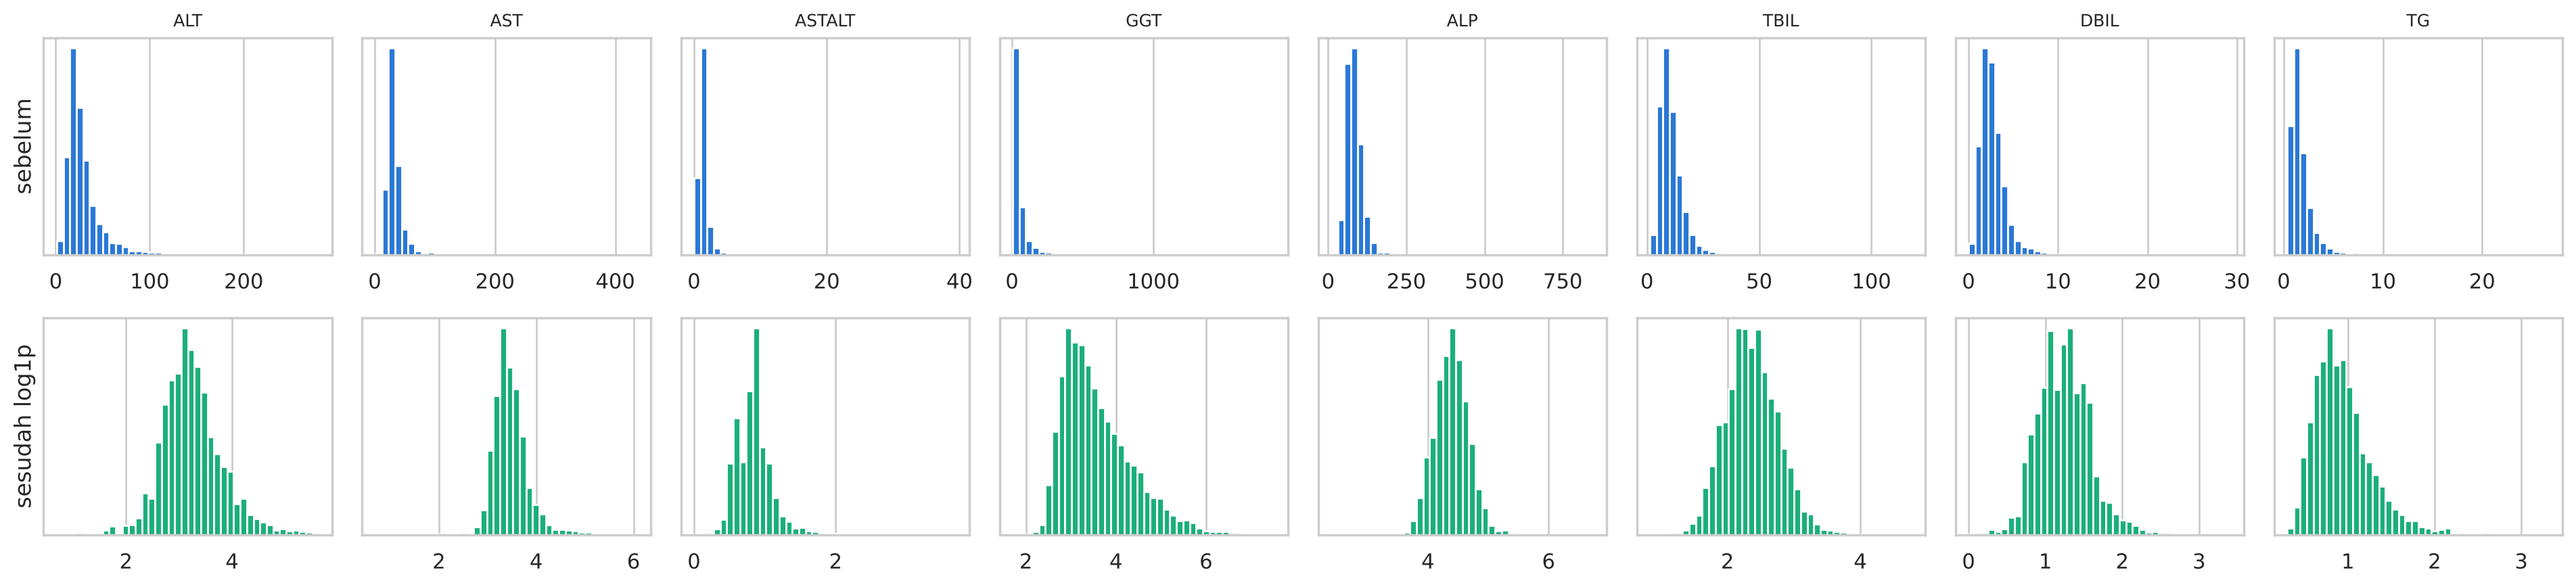

In [12]:
kolom = c.kolom_log_[:8]
fig, axes = plt.subplots(2, len(kolom), figsize=(2.4 * len(kolom), 4.5))
for j, k in enumerate(kolom):
    axes[0, j].hist(x_tr[k].dropna(), bins=40, color="#2a78d6")
    axes[0, j].set_title(k, fontsize=9); axes[0, j].set_yticks([])
    axes[1, j].hist(x_bersih[k].dropna(), bins=40, color="#1baf7a"); axes[1, j].set_yticks([])
axes[0, 0].set_ylabel("sebelum"); axes[1, 0].set_ylabel("sesudah log1p")
plt.tight_layout(); plt.show()

### Feature Set

untuk RQ1 (apakah lab rutin menambah informasi):
- **F1 non-lab**: yg bisa didapat tanpa ambil darah: demografi, antropometri, tensi, gaya hidup, riwayat penyakit.
- **F2 combined**: F1 + lab rutin non-glikemik (hati, lipid, ginjal, urin, darah lengkap).
- **cdrs**: 6 komponen Chinese Diabetes Risk Score, pembanding klinis.

feature set ini adalah kolom **input** ke `stats_cleaner`. kolom yg terlalu kosong / jarang / berkorelasi tinggi tetap dibuang di dalam fold.

In [13]:
fs = feature_sets(x)
for nama, kolom in fs.items():
    print(f"{nama} ({len(kolom)}):", kolom)

F1_nonlab (42): ['Age', 'Height', 'Weight', 'BMI', 'waist1', 'Waist2', 'hip', 'WHR', 'leg', 'HR', 'Bpsys', 'Bpdia', 'Fat', 'HypertenHis', 'DyslipideHis', 'Smoking', 'SmokingRange', 'Drinking', 'Drink50g', 'DrinkYears', 'Tea', 'Angina', 'Arrhythmia', 'PAD', 'Hyper16', 'Hyper13', 'Blind', 'Cancer', 'CerebralHe', 'CerebralIn', 'TIA', 'MI', 'HF', 'CAP', 'Hypo14', 'RF', 'Amputation', 'WeightLoss', 'DMfamilyHistory', 'cataract', 'male', 'riwayat_tidak_diisi']
F2_combined (93): ['Age', 'Height', 'Weight', 'BMI', 'waist1', 'Waist2', 'hip', 'WHR', 'leg', 'HR', 'Bpsys', 'Bpdia', 'Fat', 'ALT', 'AST', 'ASTALT', 'GGT', 'ALP', 'TBIL', 'DBIL', 'TP', 'ALB', 'HbsAg', 'HCVAb', 'CHOL', 'TG', 'HDL', 'LDL', 'BUN', 'SCRE', 'SUA', 'UCRE', 'UmALB', 'UMAUCR', 'WBC', 'LC', 'LCcount', 'ALY', 'ALYcount', 'RBC', 'RDWCV', 'RDWSD', 'MCV', 'HCT', 'LYMPH', 'LYMPHcount', 'MCH', 'MCHC', 'MPV', 'BASO', 'BASOcount', 'EO', 'EOcount', 'HGB', 'PLT', 'PDW', 'PCT', 'MONO', 'MONOcount', 'NEUT', 'NEUTcount', 'FIB4', 'PLCR', 'Hyp

### Bukti Kebocoran

`VAR00001` dan `ThalussemiaAND` dibuang sebagai bocor (alasannya ada di `laporan`). dua bukti, keduanya dihitung di sel di bawah:

1. **hubungan dengan glukosa dan label** (seluruh populasi skrining, karena ini fakta tentang kolom, bukan evaluasi model): `VAR00001` bernilai 9 hanya bila FPG >= 6,1. `ThalussemiaAND` hampir persis aturan `MCV < 80` DAN kelas >= 1, jadi diturunkan dari label.
2. **ablasi** (bagian latih saja): kolom ditambahkan kembali ke fitur dasar, lalu macro-AUC dibandingkan. fitur dasar = hasil `prepare()`.

`ThalussemiaOR`, `ThalussemiaHPLC`, `DMhighrisk` ditahan dan diuji bersama sebagai satu kelompok. model sederhana tanpa tuning: HistGradientBoosting (NaN dibiarkan) dan Logistic Regression (imputasi median). dua skema di dalam bagian latih: temporal (70% awal vs 30% akhir) dan acak (5 lipatan, rata-rata dan simpangan baku). `stats_cleaner` di-fit ulang di tiap lipatan.

In [14]:
x_penuh, _, _, _ = prepare(raw, config(buang_flag_turunan_tes=False, kebijakan_mencurigakan="keep"))
kolom_uji = ["VAR00001", "ThalussemiaAND", "ThalussemiaOR", "ThalussemiaHPLC", "DMhighrisk"]
x_dasar = x_penuh.drop(columns=kolom_uji)
assert list(x_dasar.columns) == list(x.columns) and x_penuh.index.equals(y.index)

# 1. hubungan dengan glukosa dan label
v9 = x_penuh["VAR00001"] == 9
fpg_tinggi = meta["FPG"] >= 6.1
print(f"VAR00001 = 9: {int(v9.sum())} orang | di antaranya FPG < 6,1: {int((v9 & ~fpg_tinggi).sum())} | "
      f"dari {int(fpg_tinggi.sum())} orang FPG >= 6,1, yang bernilai 9: {v9[fpg_tinggi].mean():.0%}")
ada_mcv = x_penuh["MCV"].notna()
aturan = ((x_penuh["MCV"] < 80) & (y >= 1)).astype(int)
thal = x_penuh["ThalussemiaAND"].fillna(0)
print(f"ThalussemiaAND = 1 di kelas NGR: {int(((x_penuh['ThalussemiaAND'] == 1) & (y == 0)).sum())} orang, di kelas abnormal: {int(((x_penuh['ThalussemiaAND'] == 1) & (y >= 1)).sum())} orang")
print(f"ThalussemiaAND cocok dengan aturan (MCV < 80 DAN kelas >= 1): {(thal[ada_mcv] == aturan[ada_mcv]).mean():.1%} dari {int(ada_mcv.sum())} orang")

VAR00001 = 9: 595 orang | di antaranya FPG < 6,1: 0 | dari 862 orang FPG >= 6,1, yang bernilai 9: 69%
ThalussemiaAND = 1 di kelas NGR: 2 orang, di kelas abnormal: 367 orang
ThalussemiaAND cocok dengan aturan (MCV < 80 DAN kelas >= 1): 99.7% dari 5824 orang


In [15]:
# 2. ablasi, bagian latih saja
x_penuh_tr = x_penuh.iloc[idx_latih].reset_index(drop=True)
x_dasar_tr = x_penuh_tr.drop(columns=kolom_uji)
varian = {
    "dasar": x_dasar_tr,
    "+ ThalussemiaAND": x_penuh_tr[list(x_dasar_tr.columns) + ["ThalussemiaAND"]],
    "+ VAR00001": x_penuh_tr[list(x_dasar_tr.columns) + ["VAR00001"]],
    "+ 3 kolom ditahan": x_penuh_tr[list(x_dasar_tr.columns) + ["ThalussemiaOR", "ThalussemiaHPLC", "DMhighrisk"]],
}
model = {
    "HistGB": ("none", lambda: HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=0)),
    "LogReg": ("median", lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))),
}

def macro_auc_per_lipatan(x_varian, skema):
    baris = []
    for i_latih, i_uji in buat_split(y_tr, meta_tr, skema):
        baris.append({})
        for nama, (imputasi, buat) in model.items():
            xl, xu, _ = terapkan_lipatan(x_varian, i_latih, i_uji, imputasi=imputasi)
            p = buat().fit(xl, y_tr.iloc[i_latih]).predict_proba(xu)
            baris[-1][nama] = metrik_tiga_kelas(y_tr.iloc[i_uji], p)["macro_auc"]
    return pd.DataFrame(baris)

rata, sd = {}, {}
for skema in ["temporal", "acak"]:
    for nama, x_varian in varian.items():
        r = macro_auc_per_lipatan(x_varian, skema)
        for m in model:
            rata[(nama, f"{skema} {m}")] = r[m].mean()
            sd[(nama, f"{skema} {m}")] = r[m].std() if len(r) > 1 else np.nan

rata = pd.Series(rata).unstack()[[f"{s} {m}" for s in ["temporal", "acak"] for m in model]].loc[list(varian)]
sd = pd.Series(sd).unstack()[rata.columns].loc[list(varian)]
selisih = rata.sub(rata.loc["dasar"], axis=1)
print("macro-AUC (acak: rata-rata 5 lipatan):")
display(rata.round(3))
print("simpangan baku antar lipatan (acak):")
display(sd.filter(like="acak").round(3))
print("selisih terhadap fitur dasar:")
display(selisih.round(3))

macro-AUC (acak: rata-rata 5 lipatan):


,temporal HistGB,temporal LogReg,acak HistGB,acak LogReg
dasar,0.709,0.717,0.712,0.723
+ ThalussemiaAND,0.843,0.830,0.828,0.821
+ VAR00001,0.806,0.808,0.833,0.832
+ 3 kolom ditahan,0.718,0.719,0.711,0.725


simpangan baku antar lipatan (acak):


,acak HistGB,acak LogReg
dasar,0.009,0.018
+ ThalussemiaAND,0.010,0.012
+ VAR00001,0.014,0.022
+ 3 kolom ditahan,0.011,0.017


selisih terhadap fitur dasar:


,temporal HistGB,temporal LogReg,acak HistGB,acak LogReg
dasar,0.000,0.000,0.000,0.000
+ ThalussemiaAND,0.133,0.113,0.115,0.098
+ VAR00001,0.097,0.091,0.121,0.109
+ 3 kolom ditahan,0.008,0.001,-0.001,0.001


- `VAR00001` = 9 tidak pernah muncul pada FPG < 6,1, dan `ThalussemiaAND` cocok 99,7% dengan aturan yang memakai label. keduanya turunan hasil tes / label, bukan sifat pasien.
- menambahkan kembali `ThalussemiaAND` menaikkan macro-AUC sekitar 0,10 sampai 0,13, dan `VAR00001` sekitar 0,09 sampai 0,12, di kedua model dan kedua skema. simpangan baku antar lipatan acak hanya 0,009 sampai 0,022, jadi kenaikan ini jauh di atas noise: jalan pintas, bukan sinyal.
- tiga kolom yang ditahan (`ThalussemiaOR`, `ThalussemiaHPLC`, `DMhighrisk`) mengubah macro-AUC paling jauh 0,008, tidak terbedakan dari noise. tetap dibuang karena tidak menambah apa-apa dan definisinya tidak jelas.
- di dalam bagian latih, skor temporal hampir sama dengan acak (dasar 0,709 / 0,717 vs 0,712 / 0,723). versi sebelumnya (dihitung di seluruh data) mendapat temporal 0,655 / 0,674. artinya penurunan itu berasal dari blok 30% terakhir, yaitu bagian uji sekarang. blok itu juga punya prevalensi lebih rendah (DM 3,9% vs 5,8% di latih), jadi skor di test set kemungkinan besar lebih rendah dari skor CV.

### Audit Satu Fitur

pemeriksaan tambahan untuk kebocoran yg belum diketahui: setiap fitur F2 diuji sendirian (bagian latih saja). seberapa bagus satu fitur memisahkan abnormal vs NGR (AUC), baik dari nilainya maupun dari pola kosongnya. kalau ada fitur dengan AUC sangat tinggi (> 0,75), curigai bocor.

In [16]:
def auc_satu_fitur(nilai, target):
    try:
        a = roc_auc_score(target, nilai)
        return max(a, 1 - a)
    except ValueError:
        return np.nan

y_abn_tr = (y_tr >= 1).astype(int)
audit = pd.DataFrame([{
    "fitur": k,
    "feature_set": "non-lab" if k in fs["F1_nonlab"] else "lab",
    "auc_nilai": auc_satu_fitur(x_tr[k].fillna(x_tr[k].median()), y_abn_tr),
    "auc_kosong": auc_satu_fitur(x_tr[k].isna().astype(int), y_abn_tr),
    "kosong_%": x_tr[k].isna().mean() * 100,
} for k in fs["F2_combined"]]).sort_values("auc_nilai", ascending=False).round(3)

print("fitur dengan auc_nilai > 0,75 :", int((audit["auc_nilai"] > 0.75).sum()))
print("fitur dengan auc_kosong > 0,6 :", int((audit["auc_kosong"] > 0.6).sum()))
audit.head(10)

fitur dengan auc_nilai > 0,75 : 0
fitur dengan auc_kosong > 0,6 : 0


,fitur,feature_set,auc_nilai,auc_kosong,kosong_%
16,GGT,lab,0.650,0.503,1.192
0,Age,non-lab,0.639,0.500,0.000
10,Bpsys,non-lab,0.627,0.501,0.268
11,Bpdia,non-lab,0.618,0.501,0.268
7,WHR,non-lab,0.617,0.500,0.024
4,waist1,non-lab,0.613,0.500,0.024
13,ALT,lab,0.597,0.502,0.414
14,AST,lab,0.595,0.502,0.389
5,Waist2,non-lab,0.594,0.500,0.049
61,FIB4,lab,0.593,0.504,1.289


### Pemeriksaan Akhir

memastikan kolom yang sudah diketahui bocor tidak ada di fitur akhir. ini pemeriksaan nama kolom, bukan jaminan tidak ada kebocoran lain: pilihan kolom bertumpu pada kamus data, analisis EDA, dan bukti di atas.

In [17]:
terlarang = {"FPG", "PG2h", "GLU", "HbA1c", "DM", "PGclass3", "PGclass6", "VAR00001", "ThalussemiaAND",
             "FINS", "FCP", "HomaIR", "DMhis", "DMhighrisk"}
print("kolom terlarang masih ada di hasil prepare():", sorted(terlarang & set(x.columns)))

kolom terlarang masih ada di hasil prepare(): []


### Simpan

| file | isi |
|---|---|
| `diabetes_prepared.csv` | hasil `prepare()` + `NO`, `Data`, `split`, target (`y3`, `y_dm`, `y_abn`). NaN belum diisi |
| `feature_sets.json` | daftar kolom F1 / F2 / lab / CDRS, skema split, ukuran data |
| `kolom_dibuang.csv` | alasan tahap 1 (`prepare`) dan tahap 2 (`stats_cleaner` di-fit di seluruh bagian latih, sebagai gambaran) |
| `ablasi_kebocoran.csv` | macro-AUC ablasi, simpangan baku, dan selisih |
| `audit_satu_fitur.csv` | AUC satu fitur dari nilai dan dari pola kosong |

In [18]:
data = pd.concat([
    meta[["NO", "Data"]].reset_index(drop=True),
    pd.DataFrame({"split": split.to_numpy(), "y3": y.to_numpy(),
                  "y_dm": (y == 2).astype(int).to_numpy(), "y_abn": (y >= 1).astype(int).to_numpy()}),
    x.reset_index(drop=True),
], axis=1)
data.to_csv(FOLDER_OUT / "diabetes_prepared.csv", index=False)

info = {
    "skema_test": SKEMA_TEST,
    "n_total": int(len(data)),
    "n_train": int((data["split"] == "train").sum()),
    "n_test": int((data["split"] == "test").sum()),
    "target": {"y3": NAMA_KELAS, "y_dm": "1 = DM", "y_abn": "1 = prediabetes atau DM"},
    "feature_sets": fs,
}
with open(FOLDER_OUT / "feature_sets.json", "w") as f:
    json.dump(info, f, indent=2, ensure_ascii=False)

pd.concat([
    laporan.assign(tahap="prepare"),
    pd.DataFrame({"kolom": list(c.dibuang_), "alasan": list(c.dibuang_.values()), "tahap": "stats_cleaner (bagian latih)"}),
], ignore_index=True).to_csv(FOLDER_OUT / "kolom_dibuang.csv", index=False)

pd.concat({"macro_auc": rata, "sd": sd, "selisih": selisih}, axis=1).to_csv(FOLDER_OUT / "ablasi_kebocoran.csv")
audit.to_csv(FOLDER_OUT / "audit_satu_fitur.csv", index=False)

for p in sorted(FOLDER_OUT.iterdir()):
    print(p)

data/processed/ablasi_kebocoran.csv
data/processed/audit_satu_fitur.csv
data/processed/diabetes_prepared.csv
data/processed/feature_sets.json
data/processed/kolom_dibuang.csv


### Ringkasan

1. populasi skrining 5.873 orang (49 yang sudah tahu DM dikeluarkan). kelas 4.444 / 1.121 / 308.
2. dari 190 kolom, sisa 93 setelah `prepare()` (91 kolom asli ditambah `male` dan `riwayat_tidak_diisi`). dibuang: kolom bocor, label, komplikasi, teks, id, turunan kategori, dan turunan aritmetika (`ALT.1`, `GLO`, `AG`, `IDBIL`). di bagian latih, `stats_cleaner` menyisakan sekitar 80 kolom.
3. kode 9, kosong struktural, kolom bendera (kosong diasumsikan 0), dan nilai tidak wajar ditangani eksplisit. asumsi kolom bendera belum bisa diverifikasi dari kamus data.
4. dua kolom bocor terbukti dibuang (`VAR00001`, `ThalussemiaAND`), plus tiga kolom mencurigakan sebagai pengaman. audit satu fitur tidak menemukan fitur lain dengan AUC > 0,75.
5. test set dikunci dengan skema temporal: 4.111 latih (10 Feb – 12 Mar 2012), 1.762 uji (12 Mar – 7 Apr 2012). prevalensi di uji lebih rendah.
6. langkah statistik (`stats_cleaner`) tidak disimpan di sini. ia di-fit ulang di tiap fold di `02-modeling.ipynb`.